# Tutorial sobre Radar Cross Section (RCS)

Este notebook apresenta o módulo de seção reta radar (Radar Cross Section — RCS) do Sionna RT.

Seus objetos centrais são os alvos de sensoriamento (sensing targets), ou seja, objetos da cena cujas respostas de espalhamento são descritas por modelos de espalhamento, em vez de materiais de rádio. Um modelo de espalhamento consiste em um ou vários pontos de espalhamento, cada um com sua própria RCS. Além de serem utilizados em aplicações de sensoriamento e comunicação integrados (Integrated Sensing and Communication — ISAC), os alvos de sensoriamento também são úteis para modelar objetos com geometrias complexas, para os quais o traçado de raios não é adequado.

Este notebook requer o pacote completo do Sionna, e não apenas o Sionna RT, pois utiliza ferramentas do Sionna PHY para processar e visualizar o canal de radar. A documentação da API correspondente pode ser encontrada [aqui](https://nvlabs.github.io/sionna/rt/api/rcs.html).

Neste notebook, você irá:

- Calcular o canal de radar de alvos de sensoriamento com RCS constante, utilizando o `RCSSolver`.
- Visualizar o canal de radar nos domínios distância–velocidade e angular.
- Utilizar os alvos de sensoriamento do padrão 3GPP TR 38.901, modelados por um ou vários pontos de espalhamento.
- Combinar o canal de sensoriamento com o canal de fundo calculado pelo `PathSolver`.
- Aplicar técnicas básicas de processamento de radar em um cenário urbano com vários carros em movimento.

In [1]:
# Import or install Sionna
# The full Sionna package, and not only Sionna RT, is required, as Sionna PHY
# utilities are used to process and visualize the radar channel.
try:
    import sionna.phy
except ImportError as e:
    # Only auto-install when the package itself is missing, not when a
    # transitive dependency fails to import.
    if getattr(e, "name", None) not in ("sionna", "sionna.phy"):
        raise
    import os
    import sys
    if "google.colab" in sys.modules:
        # Install Sionna in Google Colab
        print("Installing Sionna and restarting the runtime. Please run the cell again.")
        os.system("pip install sionna")
        os.kill(os.getpid(), 5)
    else:
        raise e

%matplotlib inline
import matplotlib.pyplot as plt

import mitsuba as mi
import numpy as np
import drjit as dr
import torch
from scipy.constants import speed_of_light

from sionna import rt
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, PathSolver, Camera
from sionna.rt.rcs import RCSSolver, TR38901SensingTarget, ConstantRCSSensingTarget
from sionna.phy.channel import cir_to_ofdm_channel, ofdm_to_delay_doppler_channel,\
                               subcarrier_frequencies
from sionna.phy.isac import plot_delay_doppler, plot_angular_scan, steering_vectors,\
                           angular_delay_doppler_spectrum
from sionna.phy.signal import HannWindow

no_preview = True # Toggle to False to use the preview widget
                  # instead of rendering for scene visualization

## Primeiros passos (Getting started)

Consideramos uma cena vazia com o transmissor e o receptor localizados no mesmo ponto, ou seja, uma configuração de sensoriamento monostática.

Tanto o transmissor quanto o receptor possuem uma única antena isotrópica, e o alvo de sensoriamento apresenta uma seção transversal de radar (Radar Cross Section - RCS) constante \\(\sigma\\), que preserva a polarização.

Calculamos o canal de radar utilizando o `RCSSolver`, comparamos a potência recebida com o resultado previsto pela equação do radar e visualizamos o canal de radar no domínio distância–velocidade.

A equação geral do radar é dada por:

\\[ P_r = P_t \frac{G_t G_r \lambda^2 \sigma}{(4\pi)^3 R_t^2 R_r^2} \\]

em que:

- \\(G_t\\) e \\(G_r\\) são os ganhos das antenas de transmissão e recepção;
- \\(R_t\\) e \\(R_r\\) são as distâncias entre o alvo e o transmissor e entre o alvo e o receptor, respectivamente;
- \\(P_t\\) e \\(P_r\\) são as potências transmitida e recebida, respectivamente.

Para uma configuração monostática com antenas de ganho unitário, essa equação é simplificada para:

\\[ P_r = P_t \frac{\lambda^2 \sigma}{(4\pi)^3 R_t^4}. \\]

Em um radar monostático, o deslocamento Doppler causado por um alvo que se move com velocidade radial \\(v_r\\) é dado por:

\\[ f_D = -\frac{2v_r}{\lambda}, \\]

em que a velocidade radial corresponde à projeção do vetor velocidade do alvo \\(\mathbf{v}\\) sobre a direção que vai do radar até o alvo:

\\[ v_r = \mathbf{v}^\mathsf{T}\hat{\mathbf{r}}, \qquad \hat{\mathbf{r}} = \frac{\mathbf{p}\_{\mathrm{target}}-\mathbf{p}\_{\mathrm{radar}}} {\left\|\mathbf{p}\_{\mathrm{target}}-\mathbf{p}\_{\mathrm{radar}}\right\|}. \\]

De acordo com a convenção de sinais utilizada pelo Sionna RT, um alvo que se afasta do radar (\\(v_r>0\\)) produz um deslocamento Doppler negativo, enquanto um alvo que se aproxima produz um deslocamento Doppler positivo.

Seguindo a convenção utilizada em radares, os mapas de distância–velocidade apresentados neste notebook exibem a velocidade \\(-v_r\\), que é positiva para alvos que se aproximam do radar.

In [2]:
scene = load_scene()
scene.frequency = 3.5e9

# Create a monostatic sensing setup with co-located transmitter and receiver
radar_position = np.array([0, 0, 0])
scene.add(Transmitter("tx", position=radar_position))
scene.add(Receiver("rx", position=radar_position))

scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             polarization="V",
                             pattern="iso")
scene.rx_array = scene.tx_array

# Create a target with constant RCS, approaching the radar at 100 m/s
sigma = 3.0 # m^2
target1 = ConstantRCSSensingTarget("st-1",
                                   sigma=sigma,
                                   position=(0, 0, 100),
                                   velocity=(0, 0, -100))
scene.add(target1)

# Compute the radar channel
rcs_solver = RCSSolver()
paths = rcs_solver(scene, max_depth=1)

# Received power and distance of the target obtained with Sionna RT.
# As the transmit power and the antenna gains are equal to one, the received
# power is the squared magnitude of the path coefficient.
a, tau = paths.cir(out_type="numpy", normalize_delays=False)
rt_power = np.abs(np.squeeze(a))**2
rt_distance = np.squeeze(tau)*speed_of_light/2

# Expected received power and distance
wavelength = scene.wavelength.numpy()[0]
distance = np.linalg.norm(target1.position.numpy()[:, 0] - radar_position)
expected_power = sigma*wavelength**2/((4*np.pi)**3*distance**4)

print(f"{'':16}{'Sionna RT':>12}{'Expected':>12}")
print(f"{'Received power':16}{rt_power:12.3E}{expected_power:12.3E}")
print(f"{'Distance [m]':16}{rt_distance:12.2f}{distance:12.2f}")

                   Sionna RT    Expected
Received power     1.109E-13   1.109E-13
Distance [m]          100.00      100.00


Em seguida, visualizamos o alvo no domínio distância-velocidade. A função abaixo gera uma sequência temporal de respostas ao impulso do canal (Channel Impulse Responses — CIRs) a partir dos desvios Doppler dos percursos, calcula as correspondentes respostas em frequência do canal OFDM e as transforma para o domínio atraso-Doppler. A função auxiliar `expected_range_velocity()` calcula a distância esperada e a velocidade radial dos alvos, que são exibidas como marcadores vermelhos.

In [3]:
def expected_range_velocity(targets, radar_position):
    """Compute the range and radial velocity of targets seen by a monostatic radar.

    :param targets: List of sensing targets.
    :param radar_position: Position of the radar [m].
    :return: List of ``(range_m, radial_velocity_mps)`` tuples. The radial
        velocity is positive for a receding target.
    """
    points = []
    for target in targets:
        radial_vector = target.position.numpy()[:, 0] - radar_position
        target_range = np.linalg.norm(radial_vector)
        radial_velocity = np.dot(target.velocity.numpy()[:, 0],
                                 radial_vector/target_range)
        points.append((target_range, radial_velocity))
    return points

def plot_range_velocity(paths, wavelength, expected_points=None):
    """Plot the channel power in the range-velocity domain.

    :param paths: Paths for which to compute the range-velocity map.
    :param wavelength: Carrier wavelength [m].
    :param expected_points: Optional list of ``(range_m, radial_velocity_mps)``
        points to display as red markers. The radial velocity is positive for
        a receding target.
    """
    subcarrier_spacing = 30e3
    num_subcarriers = 512
    num_time_steps = 200
    num_delay_bins = 32 # Only the first delay bins are shown
    bandwidth = num_subcarriers*subcarrier_spacing
    sampling_frequency = subcarrier_spacing # One sample per OFDM symbol

    # a: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
    a, tau = paths.cir(sampling_frequency=sampling_frequency,
                       num_time_steps=num_time_steps,
                       normalize_delays=False,
                       out_type="torch")

    # Sionna PHY expects a leading batch dimension
    frequencies = subcarrier_frequencies(num_subcarriers, subcarrier_spacing)
    h_f = cir_to_ofdm_channel(frequencies, a[None], tau[None])
    h_f = h_f[0, 0, 0, 0, 0] # [time, freq]
    h_dd = ofdm_to_delay_doppler_channel(h_f, l_max=num_delay_bins-1) # [doppler, delay]

    _, ax = plt.subplots(figsize=(8, 5))
    plot_delay_doppler(h_dd.abs().square(),
                       fast_time_sample_rate=bandwidth,
                       slow_time_sample_rate=sampling_frequency,
                       wavelength=wavelength,
                       domain="range_velocity",
                       ax=ax)
    if expected_points:
        points = np.asarray(expected_points, dtype=float)
        # The map shows the closing velocity, i.e., minus the radial velocity
        ax.scatter(points[:, 0], -points[:, 1], color="red",
                   marker="x", s=80, label="Expected target")
        ax.legend()

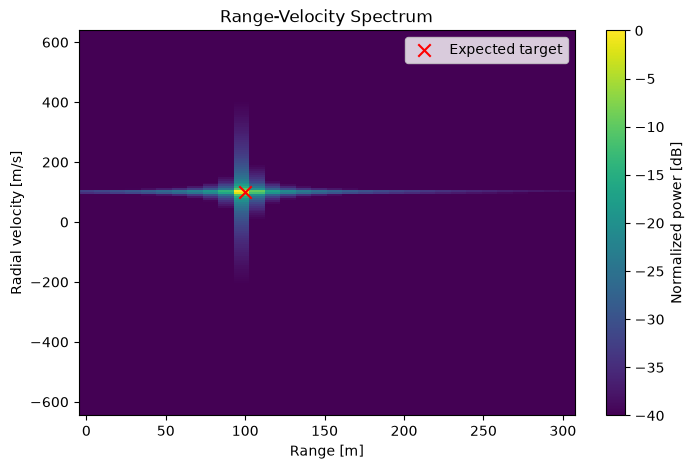

In [4]:
plot_range_velocity(paths, wavelength,
                    expected_range_velocity([target1], radar_position))

## Perguntas

1. Explique com suas palavras o gráfico acima, analisando os eixos e a distribuição de potência.
2. Por que é útil comparar o pico estimado com a posição esperada do alvo?

## Sensing com múltiplos alvos

Agora, ampliamos o cenário anterior adicionando mais dois alvos, clonados a partir do primeiro, e deslocamos os três alvos para que sejam observados em diferentes distâncias e velocidades.

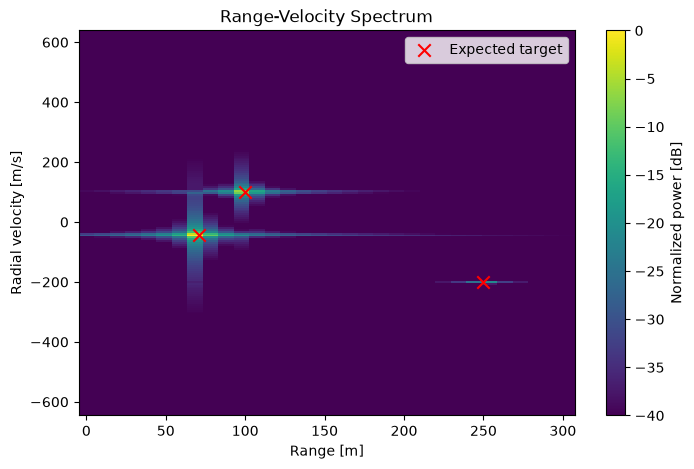

In [5]:
# Add new targets if they do not already exist
if scene.get("st-2") is None:
    target2 = target1.clone("st-2")
    target3 = target1.clone("st-3")
    scene.add([target2, target3]) # Batch add for efficiency

# Set positions and velocities
target1.position = mi.Point3f(0, 0, -100)
target1.velocity = mi.Vector3f(0, 0, 100)

target2.position = mi.Point3f(0, 50, 50)
target2.velocity = mi.Vector3f(0, 30, 30)

target3.position = mi.Point3f(0, 250, 0)
target3.velocity = mi.Vector3f(0, 200, 0)

paths = rcs_solver(scene, max_depth=1)

targets = [target1, target2, target3]
plot_range_velocity(paths, wavelength,
                    expected_range_velocity(targets, radar_position))

## Sensing com arranjos de antenas

Nesta seção, utilizamos múltiplas antenas de recepção para localizar os alvos no domínio angular. O receptor é equipado com um arranjo planar de $16 \times 16$ antenas, enquanto o transmissor permanece equipado com uma única antena.

In [6]:
scene = load_scene()
scene.frequency = 3.5e9

# Create a monostatic sensing setup with co-located transmitter and receiver
radar_position = np.array([0, 0, 0])
scene.add(Transmitter("tx", position=radar_position))
scene.add(Receiver("rx", position=radar_position))

# The receiver array is a 16x16 grid of antennas
scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             polarization="V",
                             pattern="iso")
scene.rx_array = PlanarArray(num_rows=16,
                             num_cols=16,
                             polarization="V",
                             pattern="iso")

# Create two targets with constant RCS
target1 = ConstantRCSSensingTarget("st-1",
                                   sigma=3.0,
                                   position=(100, 100, 100))
target2 = target1.clone("st-2")
target2.position = (40, -50, -20)
scene.add([target1, target2])

# Compute the radar channel
rcs_solver = RCSSolver()
paths = rcs_solver(scene, max_depth=1)

A função abaixo calcula um espectro angular correlacionando o canal observado nas antenas de recepção com vetores de direcionamento (steering vectors) para uma grade de ângulos de azimute e zênite. Os picos do espectro indicam as direções dos alvos.

In [7]:
def plot_angular_spectrum(paths, rx_array, expected_points=None):
    """Plot the channel power in the joint azimuth-zenith domain.

    The channel is evaluated at the carrier frequency. The receiver array is
    assumed to have its default orientation, with broadside along the positive
    x-axis.

    :param paths: Paths for which to compute the angular spectrum.
    :param rx_array: Planar receiver antenna array.
    :param expected_points: Optional list of ``(azimuth_deg, elevation_deg)``
        points to display as red markers.
    """
    num_angles = 181
    theta = torch.deg2rad(torch.linspace(0., 180., num_angles))   # zenith
    phi = torch.deg2rad(torch.linspace(-90., 90., num_angles))    # azimuth

    # a: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, 1]
    a, tau = paths.cir(normalize_delays=False, out_type="torch")

    # At zero baseband frequency, delays do not affect the array response.
    # Sionna PHY expects a leading batch dimension.
    # [num_rx, num_rx_ant, num_tx, num_tx_ant, 1, 1]
    h = cir_to_ofdm_channel(torch.zeros(1), a[None], tau[None])[0]

    # Array positions are normalized by wavelength, hence wavelength=1
    positions = torch.as_tensor(rx_array.normalized_positions.numpy().T)
    rx_steering = steering_vectors(positions, theta, phi, wavelength=1.)
    rx_steering = rx_steering.reshape(-1, positions.shape[0])
    tx_steering = torch.ones(1, 1, dtype=rx_steering.dtype) # Single TX antenna

    spectrum = angular_delay_doppler_spectrum(h, rx_steering, tx_steering)
    spectrum = spectrum.reshape(num_angles, num_angles)

    _, ax = plt.subplots(figsize=(7, 6))
    plot_angular_scan(spectrum, theta, phi, ax=ax)
    ax.invert_yaxis() # Zenith 0 (straight up) at the top
    if expected_points:
        points = np.asarray(expected_points, dtype=float)
        # The map shows the zenith angle, i.e., 90 deg minus the elevation
        ax.scatter(points[:, 0], 90 - points[:, 1], color="red",
                   marker="x", s=80, label="Expected target")
        ax.legend()

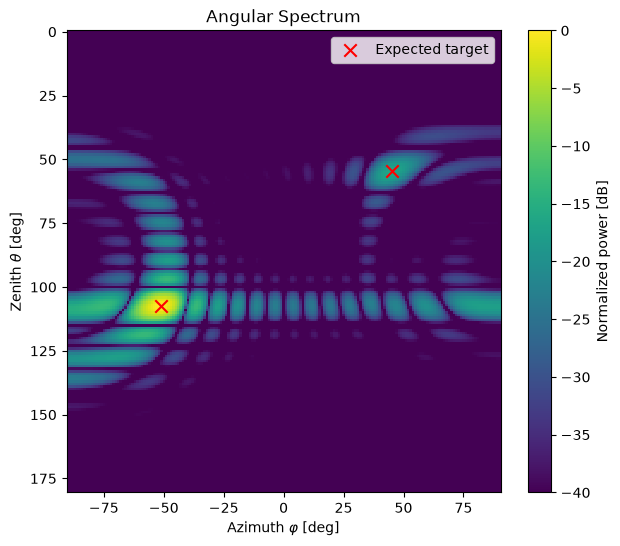

In [8]:
# Expected azimuth and elevation angles of the targets
expected_angles = []
for target in [target1, target2]:
    radial_vector = target.position.numpy()[:, 0] - radar_position
    elevation = np.rad2deg(np.arctan2(radial_vector[2],
                                      np.linalg.norm(radial_vector[:2])))
    azimuth = np.rad2deg(np.arctan2(radial_vector[1], radial_vector[0]))
    expected_angles.append((azimuth, elevation))

plot_angular_spectrum(paths, scene.rx_array, expected_angles)

## Perguntas

1. Explique com suas palavras o gráfico acima, analisando os eixos e a distribuição de potência.
2. Qual é a função da matriz de antenas receptoras nesta etapa?
3. Por que uma matriz com mais elementos pode ajudar na estimativa angular? Cite as vantagens e desvantagens.

## Sensoriamento com multipercurso e canal de fundo

O `RCSSolver` calcula apenas os percursos que interagem com um alvo de sensoriamento, ou seja, aqueles que compõem o canal de sensoriamento. Os percursos que não interagem com nenhum alvo de sensoriamento, isto é, os que compõem o canal de fundo (background channel), são calculados com o `PathSolver`. Ambos os conjuntos de percursos podem ser combinados utilizando `Paths.concat()`.

Consideramos uma configuração bistática em um cenário urbano, formado por uma rua cercada por edifícios altos, com um alvo de grandes dimensões do tipo UAV (veículo aéreo não tripulado), conforme definido na especificação 3GPP TR 38.901.

Diferentemente da cena vazia utilizada anteriormente, o canal de sensoriamento agora pode apresentar componentes de multipercurso. O número máximo de interações de um raio com a cena é controlado pelo parâmetro `max_depth` (em que o valor 1 corresponde apenas à propagação em linha de visada, ou line-of-sight — LoS).

Também é possível configurar quais tipos de interação são permitidos: propagação em linha de visada, reflexão e refração.

In [9]:
scene = load_scene(rt.scene.simple_street_canyon)
scene.frequency = 3.5e9
scene.add(Transmitter("tx", position=[34, -10, 30]))
scene.add(Receiver("rx", position=[34, 11.5, 22.5]))
scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             polarization="V",
                             pattern="iso")
scene.rx_array = scene.tx_array

# Large UAV with a single scattering point, as defined in 3GPP TR 38.901
target = TR38901SensingTarget(name="target",
                              object_type="uav-large-size",
                              model_type=2,
                              position=[0, 0, 50],
                              velocity=[0, 10, 0])
scene.add(target)

# Sensing channel computed by the RCS solver, and background channel
# computed by the path solver
rcs_solver = RCSSolver()
background_solver = PathSolver()

sensing_paths = rcs_solver(scene,
                           max_depth=5,
                           los=True,
                           specular_reflection=True,
                           refraction=False,
                           diffraction=False)

background_paths = background_solver(scene,
                                     max_depth=5,
                                     los=True,
                                     specular_reflection=True,
                                     refraction=True,
                                     diffraction=True)

all_paths = background_paths.concat(sensing_paths)

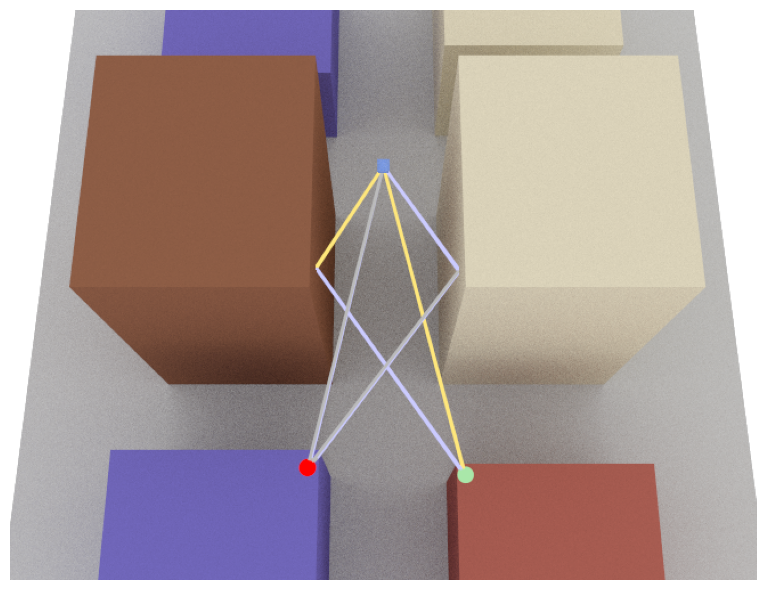

In [10]:
# Visualize the scene and the sensing paths
if no_preview:
    cam = Camera(position=[50, 0, 150], look_at=[0, 0, 0])
    scene.render(camera=cam, paths=sensing_paths);
    # scene.render(camera=cam, paths=background_paths) # Uncomment to visualize the background paths
    # scene.render(camera=cam, paths=all_paths) # Uncomment to visualize all paths
else:
    scene.preview(paths=sensing_paths)
    # scene.preview(paths=background_paths) # Uncomment to visualize the background paths
    # scene.preview(paths=all_paths) # Uncomment to visualize all paths

## Perguntas

1. Explique porque a difração e refração estão desabilitadas para o canal de sensing.
2. Por que precisamos calcular também os percursos que não interagem com o alvo?
3. No cenário acima o radar é monostático? Comente sobre as vantagens e desvantagens.

A próxima célula de código compara as respostas ao impulso do canal dos canais de fundo e de sensing.

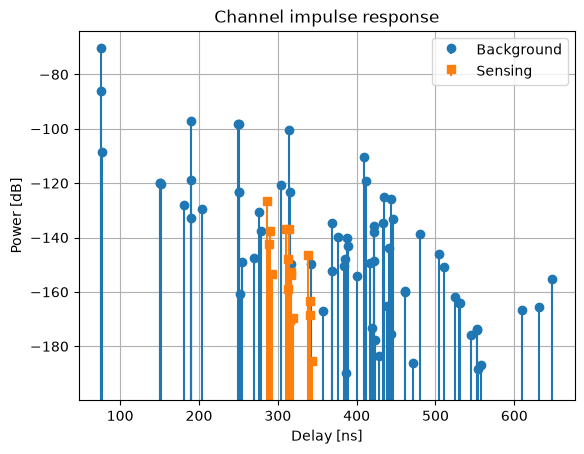

In [11]:
a_bg, tau_bg = background_paths.cir(out_type="numpy", normalize_delays=False)
a_bg = np.squeeze(a_bg)
tau_bg = np.squeeze(tau_bg)

a_sens, tau_sens = sensing_paths.cir(out_type="numpy", normalize_delays=False)
a_sens = np.squeeze(a_sens)
tau_sens = np.squeeze(tau_sens)

power_bg_db = 10.0*np.log10(np.abs(a_bg)**2)
power_sens_db = 10.0*np.log10(np.abs(a_sens)**2)
floor_db = min(power_bg_db.min(), power_sens_db.min()) - 10.0

plt.figure()
plt.stem(tau_bg*1e9, power_bg_db, bottom=floor_db,
         linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Background")
plt.stem(tau_sens*1e9, power_sens_db, bottom=floor_db,
         linefmt="C1-", markerfmt="C1s", basefmt=" ", label="Sensing")
plt.ylim(bottom=floor_db)
plt.xlabel("Delay [ns]")
plt.ylabel("Power [dB]")
plt.title("Channel impulse response")
plt.legend()
plt.grid(True)

## Perguntas

1. Com base na resposta ao impulso acima, cite pelo menos uma dificuldade enfrentada na estimação da posição de um alvo.

## Múltiplos pontos de espalhamento em um alvo de sensoriamento

O Sionna RT oferece suporte a modelos de espalhamento com múltiplos pontos de espalhamento, conforme demonstrado nas próximas células, nas quais um veículo é modelado por cinco pontos de espalhamento, de acordo com a especificação 3GPP TR 38.901.

Observe que os alvos de sensoriamento são objetos da cena associados a uma malha geométrica (mesh). A resposta de espalhamento de um alvo é determinada inteiramente pelo seu modelo de espalhamento, ou seja, sua própria malha não influencia essa resposta.

No entanto, a malha atua como um absorvedor para todos os demais percursos: qualquer raio do canal de fundo que a intercepte é descartado. Além disso, a malha pode ocultar os pontos de espalhamento de outros alvos ou bloquear os segmentos dos percursos de sensoriamento desses alvos.

In [12]:
scene = load_scene(rt.scene.simple_street_canyon)
scene.frequency = 3.5e9
scene.add(Transmitter("tx", position=[25, 0, 1.5]))
scene.add(Receiver("rx", position=[-25, 0, 1.5]))
scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             polarization="V",
                             pattern="iso")
scene.rx_array = scene.tx_array

# Vehicle modeled by multiple scattering points, as defined in 3GPP TR 38.901.
# As neither dimensions nor a mesh are specified, the target size defaults to
# the one of the TR 38.901 specifications. Setting the dimensions overrides
# these defaults, while providing a mesh uses the dimensions of its bounding box.
target = TR38901SensingTarget(name="target",
                              fname=rt.scene.low_poly_car,
                              object_type="vehicle-multi-sp",
                              model_type=2,
                              position=[0, 0, 0.8],
                              velocity=[15, 10, 0])
scene.add(target)

rcs_solver = RCSSolver()
background_solver = PathSolver()

sensing_paths = rcs_solver(scene,
                           max_depth=5,
                           los=True,
                           specular_reflection=True,
                           refraction=False)

background_paths = background_solver(scene,
                                     max_depth=5,
                                     los=True,
                                     specular_reflection=True,
                                     refraction=False,
                                     diffraction=False)

all_paths = background_paths.concat(sensing_paths)

Antes de visualizar os percursos calculados, vamos primeiro examinar o modelo de espalhamento multiponto aplicado ao alvo de sensoriamento.

Isso pode ser feito utilizando o método `show()` do objeto `TR38901SensingTarget`.

Observe que essa ferramenta abre uma janela interativa e só pode ser utilizada quando a visualização prévia estiver habilitada (`no_preview = False`).

In [13]:
if not no_preview:
    target.show(k_i = dr.normalize(mi.Vector3f(-1, 1, -1)))

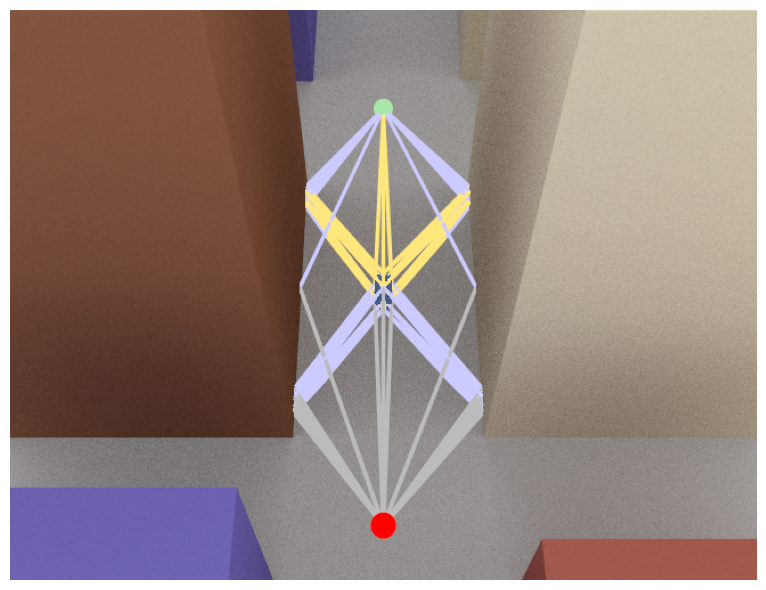

In [14]:
# No path of the background channel goes through the sensing target
if no_preview:
    cam = Camera(position=[50, 0, 80], look_at=[0, 0, 0])
    scene.render(camera=cam, paths=all_paths);
    # scene.render(camera=cam, paths=sensing_paths) # Uncomment to visualize the sensing paths
    # scene.render(camera=cam, paths=background_paths) # Uncomment to visualize the background paths
else:
    scene.preview(paths=all_paths)
    # scene.preview(paths=sensing_paths) # Uncomment to visualize the sensing paths
    # scene.preview(paths=background_paths) # Uncomment to visualize the background paths

Vamos agora calcular a resposta ao impulso do canal, para melhor visualizarmos o impacto do modelho de espalhamento do alvo sobre os percursos.

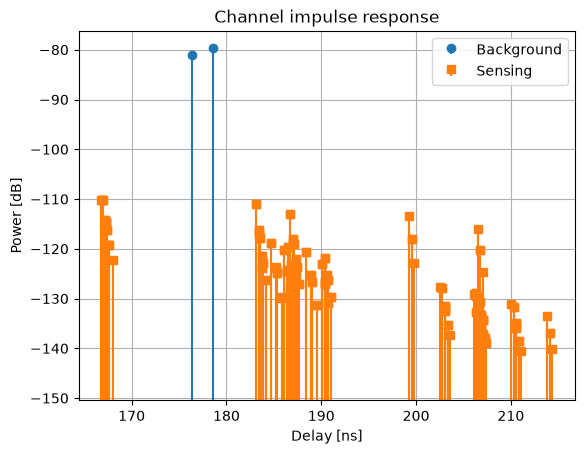

In [15]:
a_bg, tau_bg = background_paths.cir(out_type="numpy", normalize_delays=False)
a_bg = np.squeeze(a_bg)
tau_bg = np.squeeze(tau_bg)

a_sens, tau_sens = sensing_paths.cir(out_type="numpy", normalize_delays=False)
a_sens = np.squeeze(a_sens)
tau_sens = np.squeeze(tau_sens)

power_bg_db = 10.0*np.log10(np.abs(a_bg)**2)
power_sens_db = 10.0*np.log10(np.abs(a_sens)**2)
floor_db = min(power_bg_db.min(), power_sens_db.min()) - 10.0

plt.figure()
plt.stem(tau_bg*1e9, power_bg_db, bottom=floor_db,
         linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Background")
plt.stem(tau_sens*1e9, power_sens_db, bottom=floor_db,
         linefmt="C1-", markerfmt="C1s", basefmt=" ", label="Sensing")
plt.ylim(bottom=floor_db)
plt.xlabel("Delay [ns]")
plt.ylabel("Power [dB]")
plt.title("Channel impulse response")
plt.legend()
plt.grid(True)

## Perguntas

1. Por que a resposta ao impulso deste cenário, possui predominantemente percursos de sensing?
2. A consideração de que a malha do alvo atua como um absorvedor para todos os percursos com exceção dos de sensing é realista? Disserte.

## Resumo

Utilizamos o `RCSSolver` para calcular o canal de radar de alvos de sensoriamento modelados por um ou múltiplos pontos de espalhamento, validamos os resultados em relação à equação do radar e os visualizamos nos domínios distância-velocidade e angular.

Quando combinado com o canal de fundo, calculado pelo `PathSolver`, esse recurso permite simular cenários de sensoriamento realistas, incluindo efeitos de multipercurso e clutter (ecos indesejados provenientes de objetos e elementos do ambiente).